# GLORYS12V1: thermal extremes in an ocean volume

Registered reanalysis 1993–2023, reference 1993–2022. Every eighth horizontal cell and original depth indices 0,2,…,22 are retained. Midpoint layer interfaces approximate volumes. This is a decimated analysis grid, not high-resolution native-grid reconstruction. Volumetric and lineage summaries await scientific review.

Read [the tutorial guide](../docs/TUTORIALS.md) for inputs, units and configuration. Saved outputs can be read without data. Re-execution requires the optional `examples/requirements.txt` and, for real cases, the inputs in [Data](../docs/DATA.md). No download is triggered by this notebook.

## Configuration of these saved outputs

| Choice | Value |
|---|---|
| Publication | 0.1.0 |
| Source | cmems_mod_glo_phy_my_0.083deg_P1D-m |
| Reference period | 1993-01-01 through 2022-12-31 |
| Baseline / fit mode | fixed_climatology / retrospective |
| Seasonal pooling / smoothing (days) | 11 / 31 |
| Percentile estimator | hyndman_fan_7 |
| Minimum samples | 264 |
| Leap policy | hobday_366_interp |
| Within-reference correction | none |
| Representative tail / percentile / comparator | upper / 90.0 / > |
| Minimum duration / temporal gap (days) | 5 / 2 |
| Missing / join policy | as_non_exceedance / qualify_then_join |
| Declared day | native |
| Support / spatial dimensions | volume / depth, latitude, longitude |
| Domain / measure | ocean / area |
| Review status | executed; real volumetric and lineage summaries pending scientific review |

The representative definition is supplemented by the explicitly shown MCS/dynamic or TX/TN joint comparisons where present. Tracking configuration appears in its recipe cell. Full portable specs and checksums are in `report.json` and [the saved run record](../docs/run_records/glorys.json).


In [1]:
import os
import sys
from pathlib import Path

EXAMPLES = Path.cwd() if (Path.cwd() / "_data.py").exists() else Path.cwd() / "examples"
sys.path.insert(0, str(EXAMPLES))
%matplotlib inline
data_dir = Path(os.environ.get("XHW_DATA_DIR", EXAMPLES.parent / "data"))
output_dir = Path(os.environ.get("XHW_OUTPUT_DIR", EXAMPLES.parent / "outputs")) / "glorys"

## Named configurations for the example

`mhw` and the other names below are local Python aliases containing complete
DefinitionSpec values, not extra arguments or automatic presets in `xhw.detect`.
Inspect them with `.to_dict()`. The loader still declares the baseline, reference
period and grid. The volume example keeps its potential-temperature definition.


In [2]:
from profiles import example_profiles

definitions = example_profiles()
mhw, mcs = definitions["mhw"], definitions["mcs"]
ahw_tx90, ahw_tn90 = definitions["ahw_tx90"], definitions["ahw_tn90"]
ahw_txtn90 = definitions["ahw_txtn90"]
ahw_tx_then_tn90 = definitions["ahw_tx_then_tn90"]
{name: (spec.phenomenon, spec.profile) for name, spec in definitions.items()}


{'mhw': ('mhw', 'hobday2016'),
 'mcs': ('mcs', 'schlegel2021'),
 'ahw_tx90': ('ahw', 'perkins2013_tx90'),
 'ahw_tn90': ('ahw', 'perkins2013_tn90'),
 'ahw_txtn90': ('ahw', 'xhw_txtn90'),
 'ahw_tx_then_tn90': ('ahw', 'xhw_tx_then_tn90')}

In [3]:
from pathlib import Path

from _data import load_glorys
from _report import lineage_catalog_status, spatial_summary, temporal_summary, write_report
from plotting import (
    frequency_figure,
    genealogy_figure,
    largest_event,
    metrics_figure,
    sequence_figure,
    vertical_figure,
)

import xhw

print(f"Publication API: xHW {xhw.__version__}")

## Load only the registered retained cells and levels, after verifying every file

Each annual file is checksum verified before selecting cells. The 31 annual selected arrays are concatenated eagerly. Volumes use spherical coarse-cell areas times approximate retained-level thickness; all original files stay outside this repo.

In [4]:
ds, grid, baseline, definition = load_glorys(data_dir)
# Alias of the complete, case-specific definition.
mhw = definition
grid.check(ds)
print("GLORYS12V1 reanalysis 1993–2023; reference 1993–2022; stride 8; 12 retained levels.")

GLORYS12V1 reanalysis 1993–2023; reference 1993–2022; stride 8; 12 retained levels.


## Marine heatwaves at every retained ocean voxel; no interpolation in this case

MHW uses strict P90 exceedance; MCS uses strict P10 under-threshold comparison. Both use 11-day pooling, 31-day smoothing, type 7, minimum five days and gaps up to two days, qualifying runs before joining. Frequency uses valid-day support.

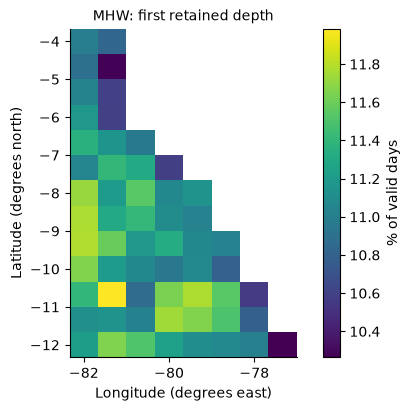

In [5]:
fitted = xhw.fit_baseline(
    ds, variable="thetao", grid=grid, baseline=baseline, definition=mhw
)
fitted.check_invariants()
mask = xhw.detect(ds, variable="thetao", grid=grid, definition=mhw, baseline_result=fitted)
mask.check_invariants()
catalog = xhw.build_catalog(mask, analysis_mode="retrospective")
catalog.check_against(mask)
figure = frequency_figure({"MHW: first retained depth": mask}, output_dir)

**Reading these figures.** Frequency maps show the percentage of occupied valid days, with both numerator and denominator restricted to valid support. Outside-domain cells are blank. Panels have individual scales; compare colorbar values rather than color alone. Differences between methods/profiles are not proof of greater scientific skill.

## Compare index and physical vertical neighbourhoods without changing the evidence

A 0 m gap gives six-face index neighbours. Physical 5 m and 20 m limits also bridge intervening layers when their thickness fits in both columns. Only patch connectivity changes, not the XMask.

In [6]:
connectivity = {}
for gap in (0.0, 5.0, 20.0):
    patches = xhw.build_objects(
        mask,
        recipe=xhw.SpatialRecipe(
            input_layer="event_membership",
            steps=(
                xhw.RecipeStep.segment(
                    footprint=xhw.Footprint.connected(1, vertical_gap_m=gap),
                    min_area=xhw.MinArea.none(),
                ),
            ),
        ),
    )
    patches.check_invariants()
    patches.check_against(mask)
    connectivity[f"{gap:g} m"] = int(patches.dataset.sizes["object"])

## Track 6-neighbour volume patches with positive shared volume and overlap >= 0.1

No minimum volume cut; six-face patches; smaller-object volume overlap ≥0.1, zero object gaps and five-day minimum tracks. The map sequence is the first retained depth; the next figure displays a vertical section without interpolation.

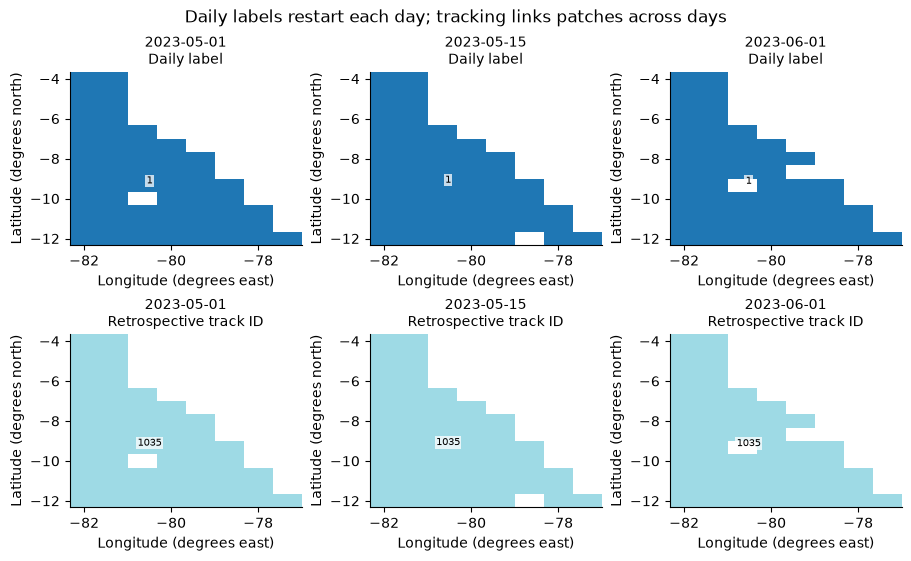

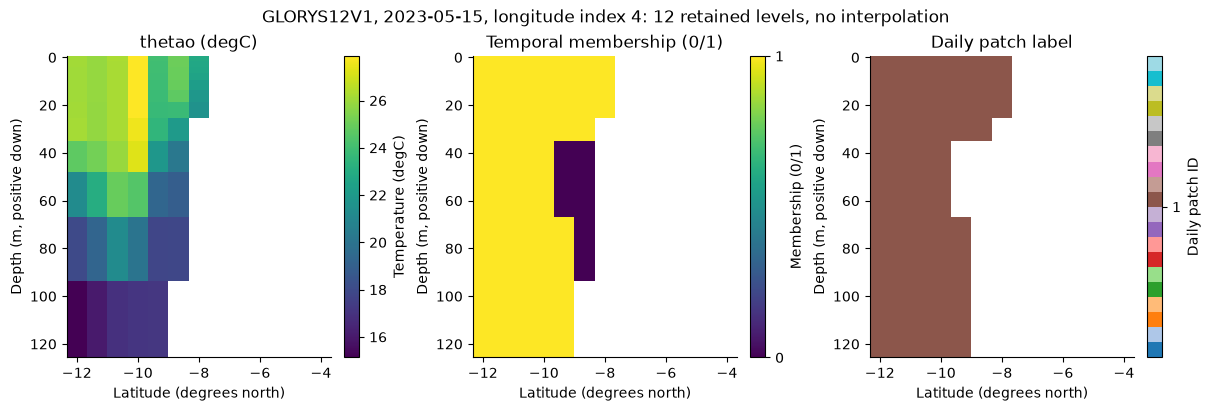

In [7]:
recipe = xhw.SpatialRecipe(
    input_layer="event_membership",
    steps=(
        xhw.RecipeStep.segment(footprint=xhw.Footprint.connected(1), min_area=xhw.MinArea.none()),
        xhw.RecipeStep.track(min_overlap=0.1, max_gap_days=0, min_duration_days=5),
    ),
)
objects = xhw.build_objects(mask, recipe=recipe, analysis_mode="retrospective")
objects.check_invariants()
objects.check_against(mask)
figure = sequence_figure(objects, ["2023-05-01", "2023-05-15", "2023-06-01"], output_dir)
figure = vertical_figure(ds, mask, objects, output_dir, date="2023-05-15")

**Reading these figures.** Top row: daily labels. Bottom: retrospective tracker IDs, annotated with actual numbers. Background and invalid support are blank; consult the validity mask to distinguish them. IDs are categorical, not magnitudes, and palettes can repeat. For the volume case this is explicitly the first retained depth.

The vertical section shows potential temperature (°C), temporal membership (0/1) and daily 3-D patch labels. Depth is metres positive down. Outside ocean support is blank. Retained-level midpoint thicknesses are approximate; no vertical interpolation or independent 2-D labelling is performed.

## Weight sizes and intensities by approximate area times retained-level thickness

Volume weights determine daily size and mean intensity. A single largest size-time event is plotted, with its first-level occupied-day footprint. Graphs keep short untracked patch components; qualification/export status is explicit.

plotting.py:72: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.savefig(output_dir / f"{name}.png", dpi=150, bbox_inches="tight")


,event_number,event_duration_days,event_n_branches,event_n_splits,event_n_merges
spacetime_event,,,,,
0,1,6,1,0,0
1,2,11,1,0,0
2,3,10,1,0,0
3,4,5,1,0,0
4,5,321,407,104,108


events.py:101: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  func(*args, **kwargs)


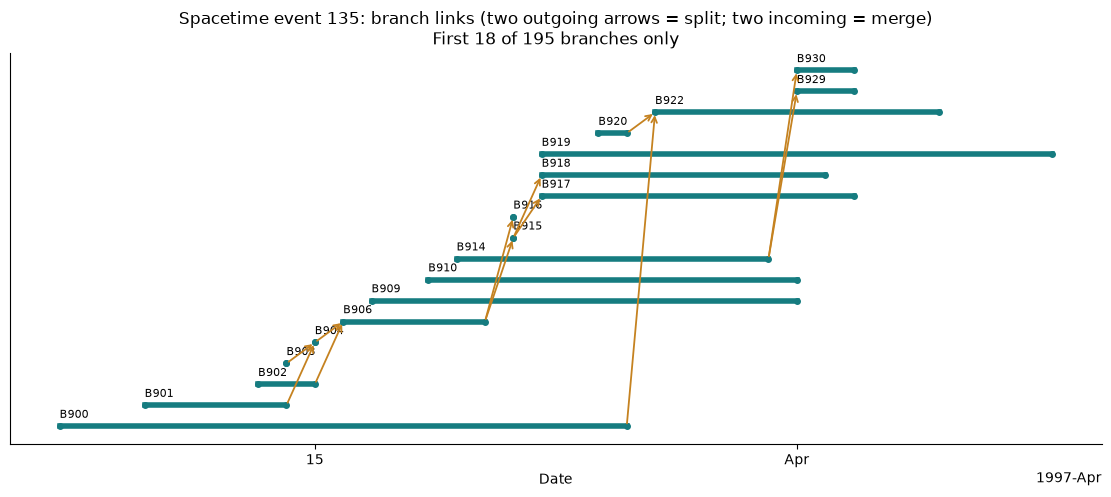

pylabtools.py:158: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


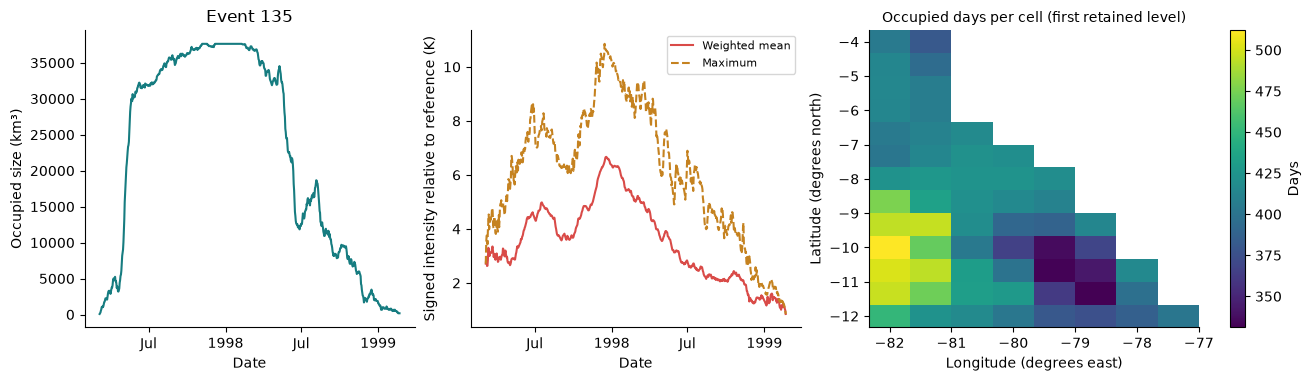

In [8]:
graph = xhw.build_lineage(objects, field=mask.intensity(), weighted=True)
graph.check_invariants()
graph.check_against(objects)
export_status = lineage_catalog_status(graph, mask)
event = largest_event(graph)
figure = genealogy_figure(graph, event, output_dir)
metrics_figure(graph, objects, event, output_dir)
del figure
weights = ds.cell_area * ds.dz
total = float(weights.where(ds.domain_mask, 0).sum())
occupied = mask.dataset.event_membership.sel(time="2023-05-15")
metrics = {
    "temporal": temporal_summary(mask, catalog),
    "spatial": spatial_summary(objects, graph),
    "patches_by_vertical_gap": connectivity,
    "domain_volume_km3": total / 1e9,
    "volume_fraction_in_event_2023_05_15": float(weights.where(occupied, 0).sum()) / total,
    "lineage_catalog_export": export_status,
}

graph.dataset[
    ["event_number", "event_duration_days", "event_n_branches", "event_n_splits", "event_n_merges"]
].isel(spacetime_event=slice(0, 5)).to_dataframe()

**Reading these figures.** Teal segments are branches and amber arrows are qualifying parent/child links. Two outgoing links indicate a split; two incoming a merge. Real diagrams mark when only the first 18 branches are displayed. This does not establish causality.

The selected event has size in km² (surface) or km³ (volume), weighted mean and maximum signed intensity relative to reference in K, and occupied days per cell. The volume map is a first-level slice. Peak size, size-time and footprint are different quantities; these figures do not represent all events at once.

## Record approximation choices and the outstanding scientific review

The report contains versions, exact specs, source checksum, selection, execution time and review status. A reproducible number is not automatically a reviewed scientific conclusion.

In [9]:
report = write_report(
    output_dir,
    "glorys",
    metrics,
    grid=grid,
    baseline=baseline,
    definition=mhw,
    recipe=recipe,
    graph=graph,
    review="executed; real volumetric and lineage summaries pending scientific review",
    extra={
        "selection": "Peru 1993–2023; horizontal stride 8; original depth indices 0,2,…,22",
        "layer_thickness_m": ds.dz.values.tolist(),
        "volume_geometry": "spherical 2/3-degree cell areas; midpoint depth interfaces",
        "decimation_limit": "coarse retained-cell connectivity cannot resolve omitted features",
        "domain_volume_units": "km3",
    },
)

{
  "temporal": {
    "events": 29597,
    "exceedance_cell_days": 912783,
    "event_cell_days": 863807,
    "joined_cell_days": 3388,
    "valid_cell_days": 7789536,
    "filled_cell_days": 0,
    "max_duration_days": 543
  },
  "spatial": {
    "patches": 25649,
    "tracks": 1041,
    "branches": 4968,
    "spacetime_events": 1041,
    "splits": 1007,
    "merges": 994,
    "max_size": 37631383867336.78,
    "size_units": "m3",
    "max_size_time": 1.5966165094361582e+16,
    "max_duration_days": 853
  },
  "patches_by_vertical_gap": {
    "0 m": 25649,
    "5 m": 25561,
    "20 m": 24759
  },
  "domain_volume_km3": 37631.383867336765,
  "volume_fraction_in_event_2023_05_15": 0.7197461985356799,
  "lineage_catalog_export": {
    "status": "exported and checked",
    "short_components": 0
  }
}


## Interpretation and provenance

Inspect the executed report and [metrics guide](https://github.com/DanielCamarena/xhw/blob/main/docs/METRICS.md). Keep domain, grid, reference, tail, missing policy, persistence, connectivity and overlap denominator attached to these numbers. Genealogy is not attribution. Figures are produced by xarray/Matplotlib, not a native xHW graphics API.

In [10]:
{
    "review_status": report["review_status"],
    "versions": report["versions"],
    "source_checksum": report["source"]["fields"]["checksum"],
}

{'review_status': 'executed; real volumetric and lineage summaries pending scientific review',
 'versions': {'xhw': '0.1.0',
  'numpy': '2.5.4',
  'xarray': '2026.7.0',
  'scipy': '1.16.3',
  'matplotlib': '3.11.2',
  'h5netcdf': '1.8.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'source_checksum': 'sha256:29d8707a43e8236faf2b60d8b43b04ce2168d37b80fa196975fae0f08c96c857'}

## Explore already computed products

Install `examples/requirements-interactive.txt` in this kernel, then use date, layer,
event/branch and cell controls. Map zoom and pan use the mouse. Date and cell sliders
update on release. Disabled event controls mean that the selected case has temporal
products only. TX+TN temperature panels show the first daily component.

The controls do not fit baselines or rerun detection/tracking. Static figures and tables
above remain readable on GitHub; these controls need a live Jupyter kernel.


In [11]:
from exploration import explorer

cases = {"MHW": (mask, objects, graph)}
explorer(cases)


### Retained-cell volume and vertical evolution

Rotate/zoom the 3-D scene. The offline HTML includes up to 60 dates around the largest
event's size peak. It draws retained cell centres, without inventing geometry between
decimated cells. Axes use degrees and metres with a visual aspect ratio, not common
physical scale. Depth increases downwards. The section GIF has fixed temperature scale.


In [12]:
from exploration import event_window, vertical_gif, volume_figure, volume_html
from IPython.display import Image, display

dates = event_window(graph)
volume_figure(mask, objects, graph, date=str(dates[0])[:10])


Offline HTML saved as volume.html in the configured output directory.


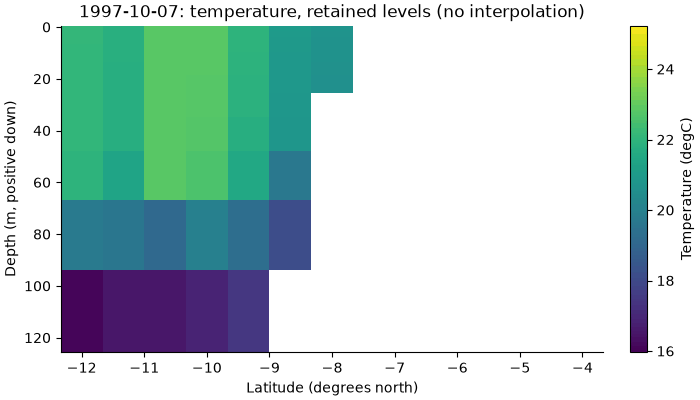

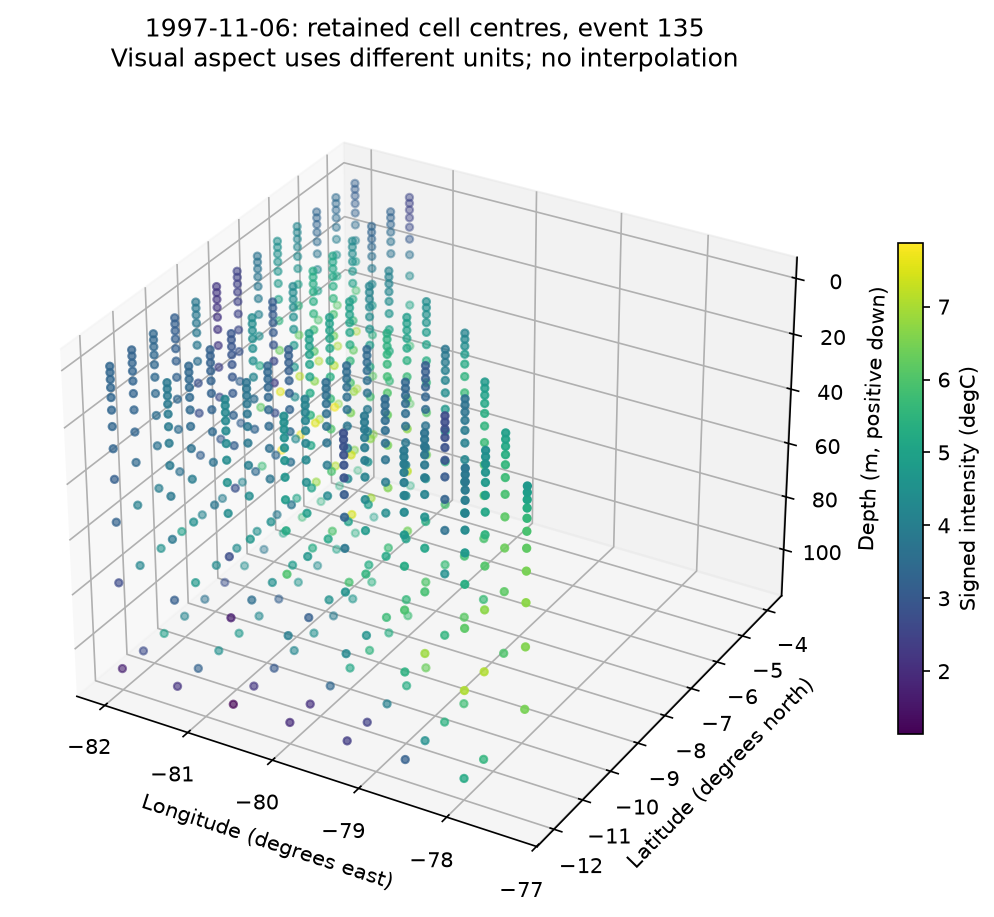

In [13]:
from exploration import volume_preview

html_path = volume_html(mask, objects, graph, output_dir)
section_path = vertical_gif(mask, objects, graph, output_dir)
print("Offline HTML saved as volume.html in the configured output directory.")
display(Image(filename=str(section_path)))
display(Image(filename=str(volume_preview(mask, objects, graph, output_dir))))
